<a href="https://colab.research.google.com/github/BarGinger/Deep_Learning_MEG/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning - Assigment 2

### Group Number: 22

### Teammates:
1. **Mahshid Jafar Tajrishi**
2. **Bar Melinarskiy**
3. **Cis van Aken**
4. **Simon van Klompenburg**

## Imports entire notebook

In [4]:
# Helper function to check if the code is running in Google Colab
def is_colab():
    try:
        import google.colab
        return True
    except ImportError:
        return False

# Usage
if is_colab():
    print("Running in Google Colab")
else:
    print("Not running in Google Colab")


# Importing libraries
import pandas as pd
import numpy as np
from scipy.io import loadmat
from IPython.display import display
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.cuda.amp import GradScaler, autocast  # Add these imports for mixed precision training
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler, TensorDataset
from torchsummary import summary
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, auc
import sklearn.preprocessing
from tqdm.auto import tqdm
import seaborn
from enum import Enum


import os
import shutil
import subprocess
import zipfile
import re
import random
import h5py




Not running in Google Colab


## Global Definitions

In [5]:
# Path to the zip file
data_dir = "./Data"
google_drive_folder = "/content/drive/MyDrive/UU"
zip_path = f"{data_dir}/Final Project data.zip"

# Set the device to GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Set pandas display options to show all columns
pd.set_option('display.max_columns', None)

# If we are in colab and we need to mount the drive
if is_colab():
  from google.colab import drive
  # Mount Google Drive
  drive.mount('/content/drive')
  print("Google Drive mounted successfully.")
  zip_path = f"{google_drive_folder}/Final Project data.zip"
else:
  print("Not in Google Colab.")

Not in Google Colab.


In [6]:
# Check if CUDA is available
print(torch.__version__)
print(torch.version.cuda)  # Should match CUDA 12.5
print(torch.backends.cudnn.version())  # Should return a version, not None
print(torch.cuda.is_available())  # Should return True

2.7.0+cu126
12.6
90701
True


### Extract the Zip File

In [4]:
# Check if the dataset is already extracted, if not extract it
if not os.path.exists(data_dir):
    print("Extracting the dataset...")
    #unzip
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(data_dir)
    #list files in the extracted dir
    os.listdir(data_dir)
else:
    print("Dataset already extracted.")

Dataset already extracted.


## Utils

In [7]:
import h5py

def get_dataset_from_h5py(filename_path):
    """
        Get the dataset from the h5py file.
        Parameters:
        filename_path (str): The path to the h5py file.
        Returns:
        matrix (numpy.ndarray): The dataset as a numpy array.
    """

    matrix = None
    try:
        with h5py.File(filename_path, 'r') as f:
            # List all datasets or groups in the file
            avilable_datasets = list(f.keys())
            if len(avilable_datasets) == 0:
                print("No datasets or groups found in the file.")
            else:
                print(f"Available datasets file {filename_path}: {avilable_datasets}")

            dataset_name = avilable_datasets[0]
            # Check if the dataset exists in the file
            if dataset_name in f:
                matrix = f.get(dataset_name)[()]
            else:
                print(f"Dataset '{dataset_name}' not found in the file.")
    except OSError as e:
        print(f"Error opening file {filename_path}: {e}")
    except Exception as e:
        print(f"An error occurred: {e}")

    return torch.tensor(matrix)


# Load Data

In [8]:
matrix = get_dataset_from_h5py(f"{data_dir}/Cross/test1/task_story_math_162935_6.h5")
if matrix is not None:
    print(f"Matrix shape: {matrix.shape}")

Available datasets file ./Data/Cross/test1/task_story_math_162935_6.h5: ['task_story_math_162935']
Matrix shape: torch.Size([248, 35624])


# Visualize data (maybe try one of every task to get some intuition)

tensor(-4.0694e-11, dtype=torch.float64)


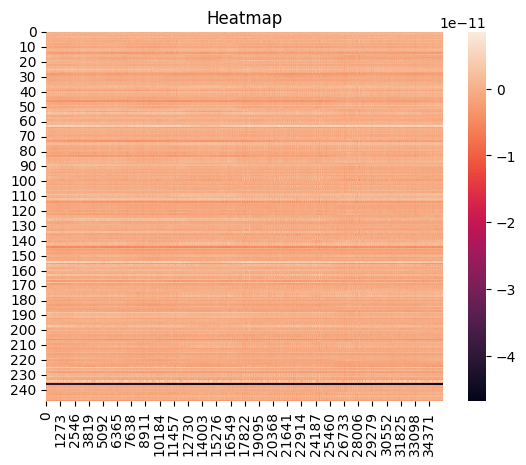

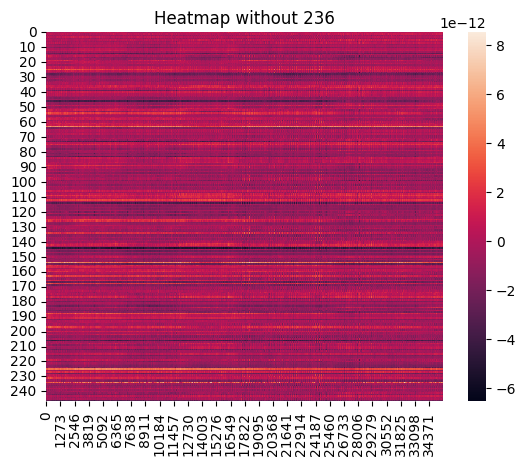

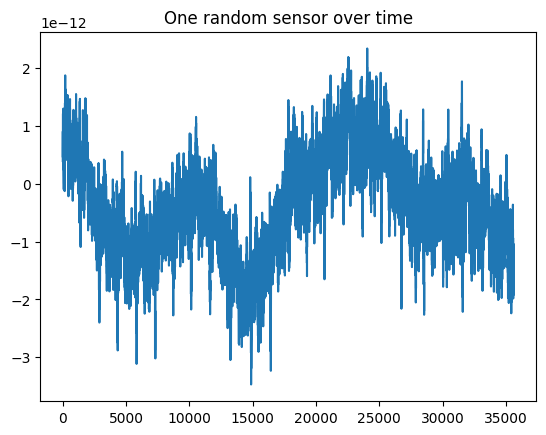

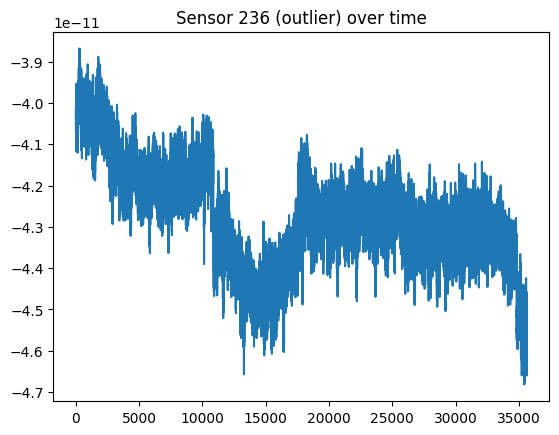

In [21]:
print(matrix[236,0])
seaborn.heatmap(matrix)
plt.title("Heatmap")
plt.show()

noOutlier = np.delete(matrix, 236, 0)
seaborn.heatmap(noOutlier)
plt.title("Heatmap without 236")
plt.show()

plt.plot(matrix[53, :])
plt.title("One random sensor over time")
plt.show()

plt.plot(matrix[236, :])
plt.title("Sensor 236 (outlier) over time")
plt.show()

# Visualize some different tasks

Available datasets file ./Data/Intra/train/rest_105923_3.h5: ['rest_105923']
tensor(1.0018e-12, dtype=torch.float64)


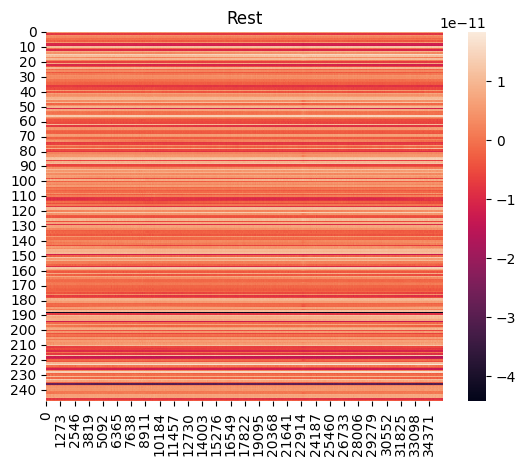

Available datasets file ./Data/Intra/train/task_motor_105923_4.h5: ['task_motor_105923']
tensor(-3.6990e-13, dtype=torch.float64)


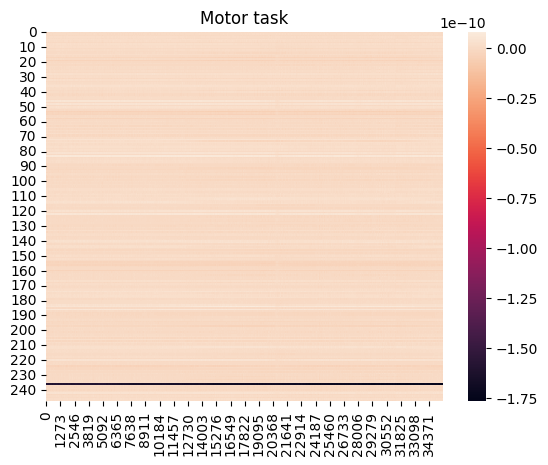

Available datasets file ./Data/Intra/train/task_story_math_105923_6.h5: ['task_story_math_105923']
tensor(1.1565e-12, dtype=torch.float64)


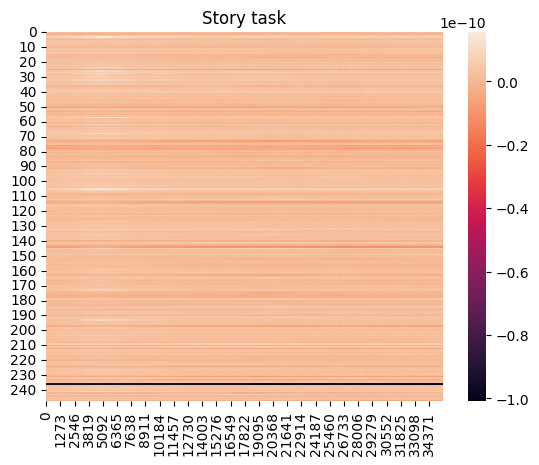

Available datasets file ./Data/Intra/train/task_working_memory_105923_2.h5: ['task_working_memory_105923']
tensor(9.3185e-13, dtype=torch.float64)


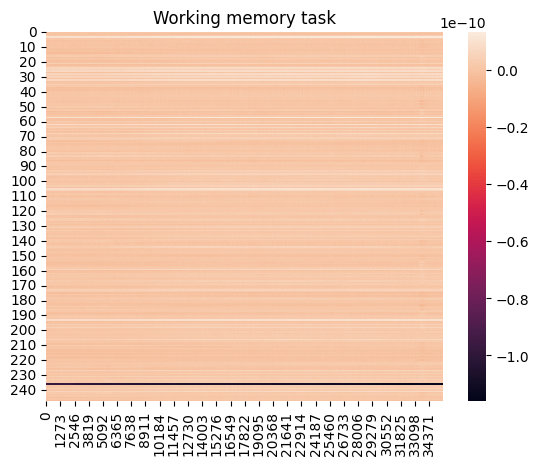

In [23]:
matrix1 = get_dataset_from_h5py(f"{data_dir}/Intra/train/rest_105923_3.h5")
print(torch.mean(matrix1))
seaborn.heatmap(matrix1)
plt.title("Rest")
plt.show()

matrix2 = get_dataset_from_h5py(f"{data_dir}/Intra/train/task_motor_105923_4.h5")
print(torch.mean(matrix2))
seaborn.heatmap(matrix2)
plt.title("Motor task")
plt.show()

matrix3 = get_dataset_from_h5py(f"{data_dir}/Intra/train/task_story_math_105923_6.h5")
print(torch.mean(matrix3))
seaborn.heatmap(matrix3)
plt.title("Story task")
plt.show()

matrix4 = get_dataset_from_h5py(f"{data_dir}/Intra/train/task_working_memory_105923_2.h5")
print(torch.mean(matrix4))
seaborn.heatmap(matrix4)
plt.title("Working memory task")
plt.show()

# Load all training data

In [9]:
train_data = []
tasks = ["rest", "task_motor", "task_story_math", "task_working_memory"]
for task in tasks:
    for trial in range(1,9):
        dataset = get_dataset_from_h5py(f"{data_dir}/Intra/train/{task}_105923_{trial}.h5")

        # Append this trial to the list
        train_data.append(dataset)

# Stack in 3rd dimension
train_data = torch.stack(train_data)

print(train_data.shape)

Available datasets file ./Data/Intra/train/rest_105923_1.h5: ['rest_105923']
Available datasets file ./Data/Intra/train/rest_105923_2.h5: ['rest_105923']
Available datasets file ./Data/Intra/train/rest_105923_3.h5: ['rest_105923']
Available datasets file ./Data/Intra/train/rest_105923_4.h5: ['rest_105923']
Available datasets file ./Data/Intra/train/rest_105923_5.h5: ['rest_105923']
Available datasets file ./Data/Intra/train/rest_105923_6.h5: ['rest_105923']
Available datasets file ./Data/Intra/train/rest_105923_7.h5: ['rest_105923']
Available datasets file ./Data/Intra/train/rest_105923_8.h5: ['rest_105923']
Available datasets file ./Data/Intra/train/task_motor_105923_1.h5: ['task_motor_105923']
Available datasets file ./Data/Intra/train/task_motor_105923_2.h5: ['task_motor_105923']
Available datasets file ./Data/Intra/train/task_motor_105923_3.h5: ['task_motor_105923']
Available datasets file ./Data/Intra/train/task_motor_105923_4.h5: ['task_motor_105923']
Available datasets file ./Da

# Downsample

In [ ]:
def downsample(data, factor):
    # Chatgpt suggests applying a lowpass filter
    
    # Chatgpt suggests trimming data to be divisible by factor beforehand
    
    pool = nn.AvgPool1d(factor)

    return pool(data)

# Alternative, use: scipy.signal.decimate(x, q, axis=-1), to efficiently handle low-pass filtering & downsampling

# Check

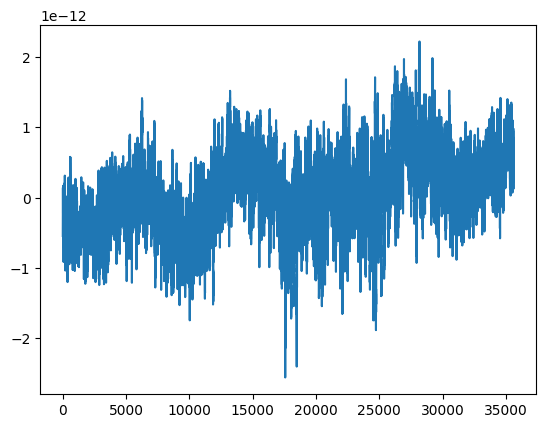

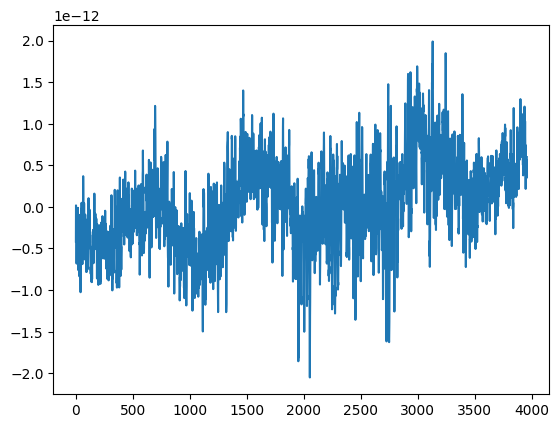

torch.Size([248, 3958])


In [29]:
channel = 176

plt.plot(matrix[channel,:])
plt.show()

plt.plot(downsample(matrix, 9)[channel, :])
plt.show()
print(downsample(matrix, 9).shape)

# Visualize time series

------------------------------------------------------


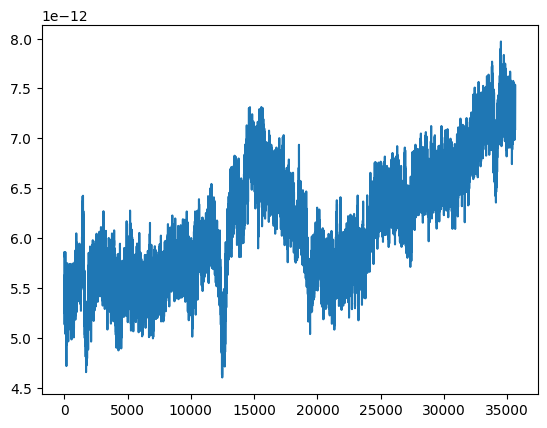

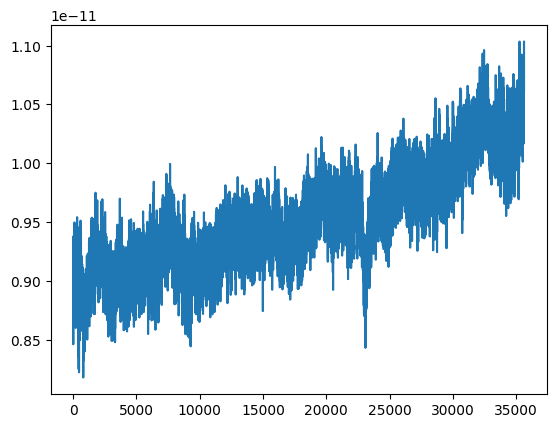

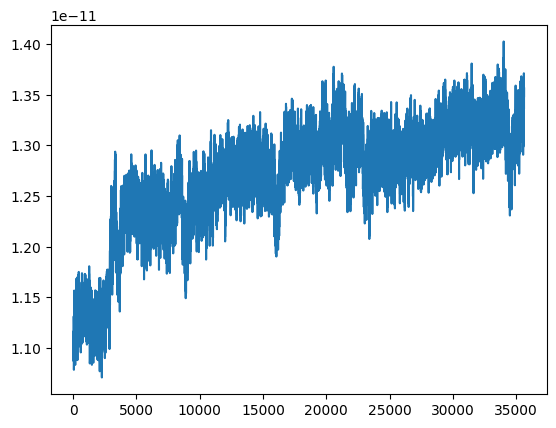

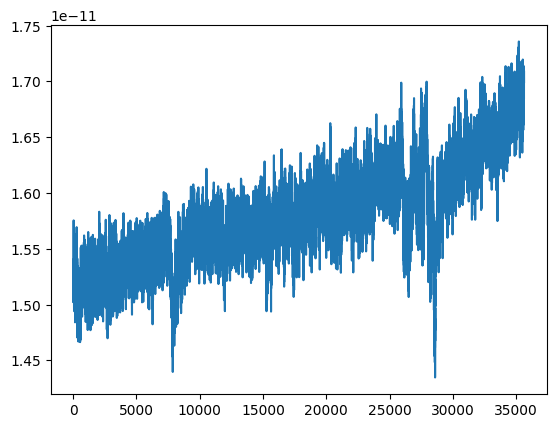

------------------------------------------------------


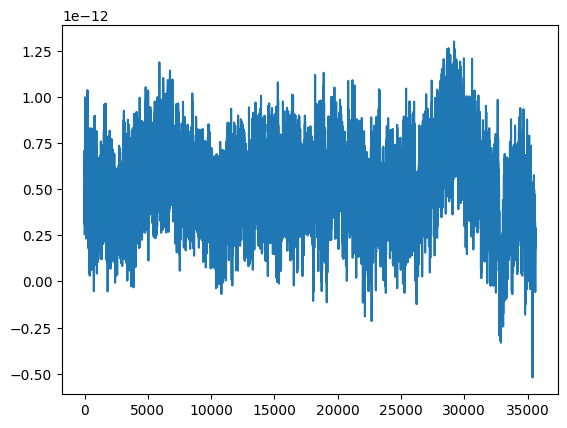

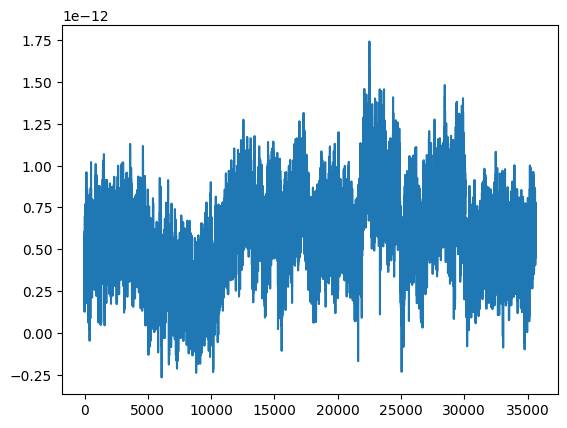

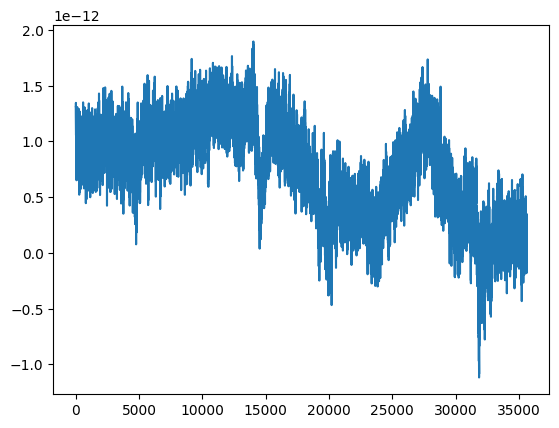

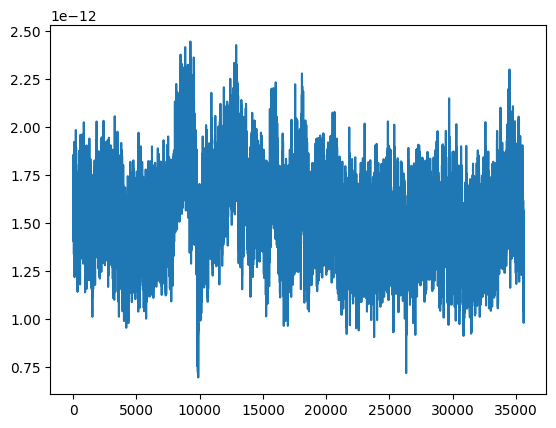

------------------------------------------------------


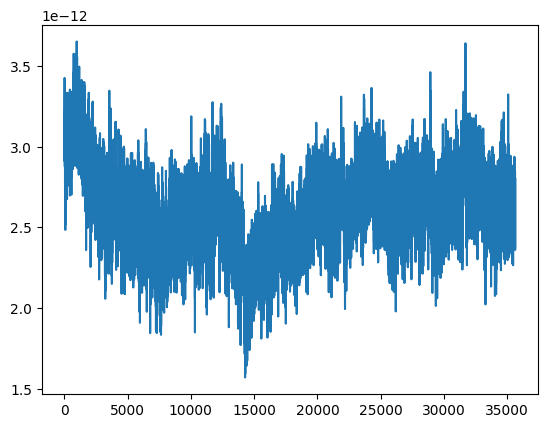

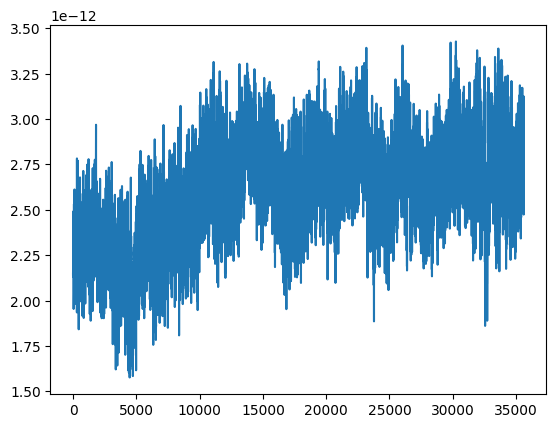

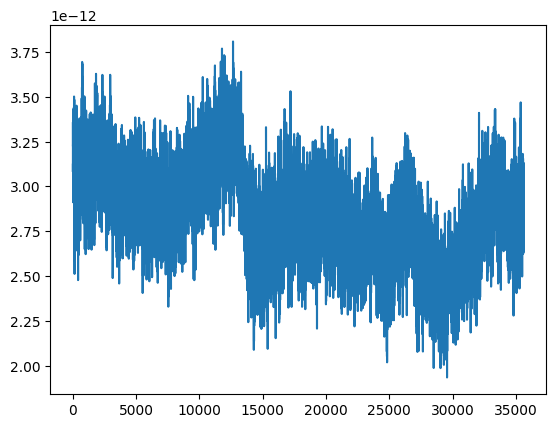

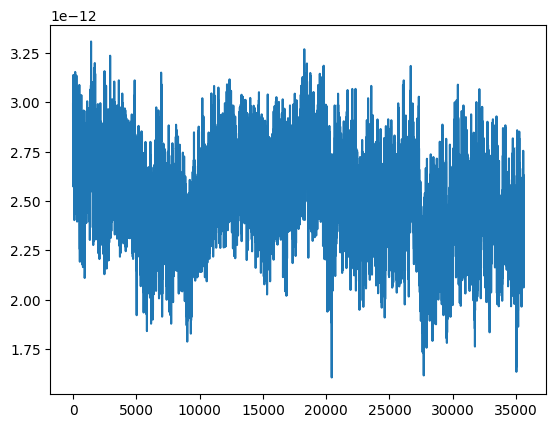

------------------------------------------------------


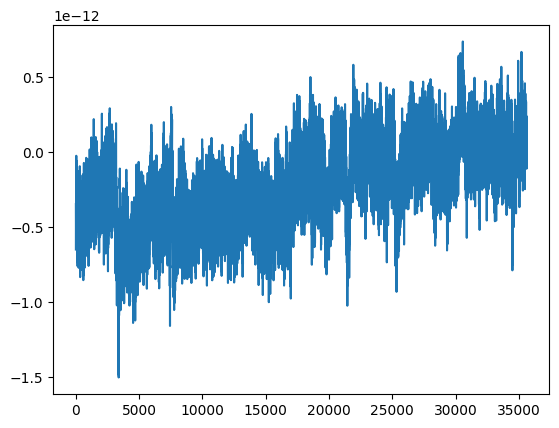

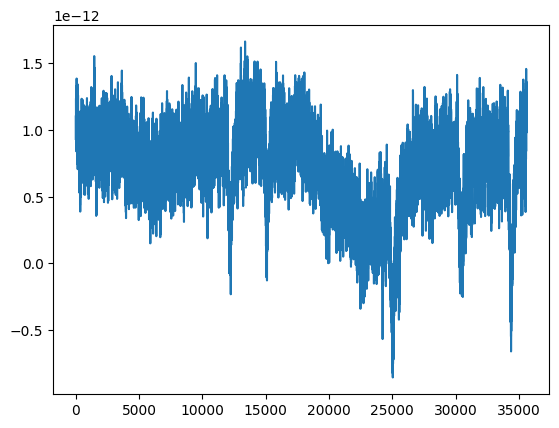

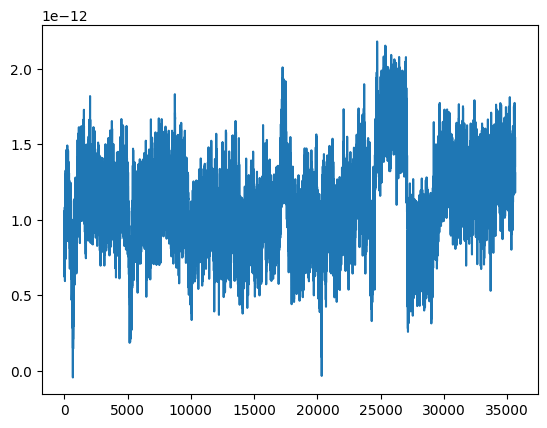

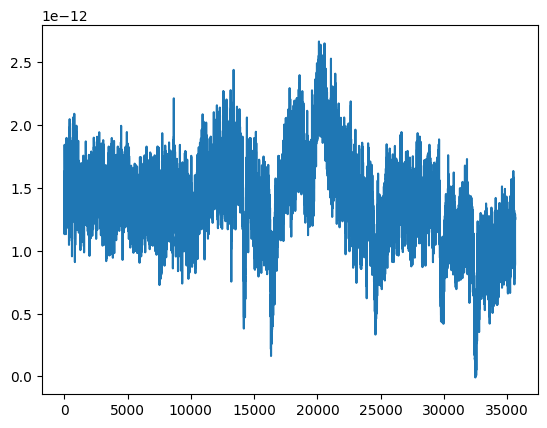

In [20]:
for trial in range(16):
    if (trial % 4 == 0):
        print("------------------------------------------------------")
    channel = 44
    plt.plot(train_data[trial*2, channel, :])
    plt.show()

# Scale data

In [33]:
class NormalizationType(Enum):
    MINMAX_LOCAL = 1
    Z_SCORE_LOCAL = 2
    Z_SCORE_TIMEWISE = 3


def scale_data(data, scaler_type):
    if(scaler_type == NormalizationType.MINMAX_LOCAL):
        scaler = sklearn.preprocessing.MinMaxScaler()
        return(scaler.fit_transform(data))
    elif(scaler_type == NormalizationType.Z_SCORE_LOCAL):
        scaler = sklearn.preprocessing.StandardScaler()
        return(scaler.fit_transform(data))
    elif(scaler_type == NormalizationType.Z_SCORE_TIMEWISE):
        mean = torch.mean(train_data, 0)
        sd = torch.std(train_data, 0)
        return((data-mean)/sd)

# Visualization

-3.4383673745698583e-17


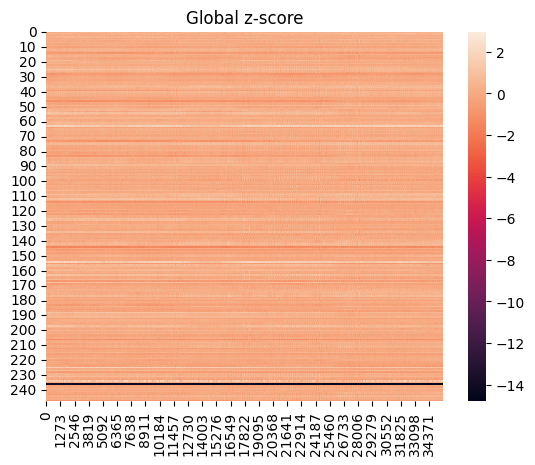

tensor(-0.4290, dtype=torch.float64)


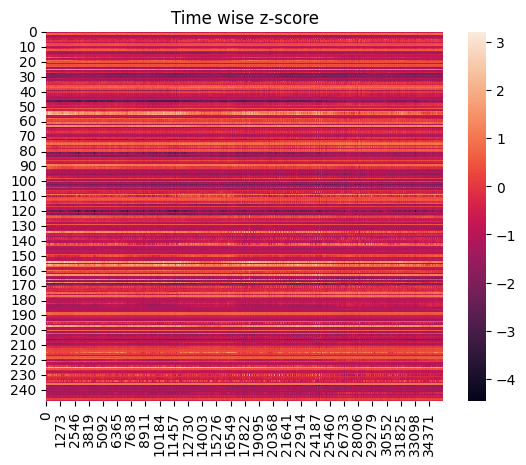

-5.0802380181467323e-17


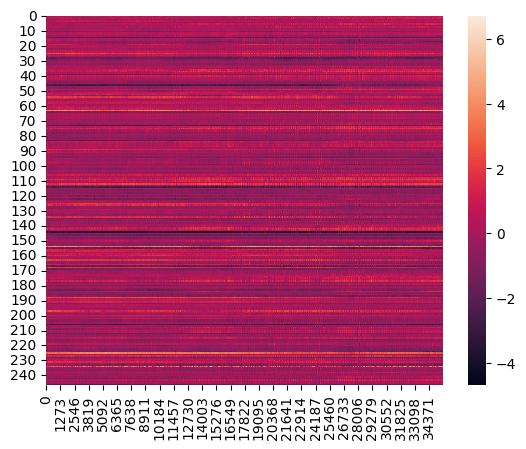

tensor([ 2.6634e-12, -7.7432e-13, -4.0694e-11, -1.5401e-12],
       dtype=torch.float64)
[  1.02670335  -0.17257275 -14.09860302  -0.43973344]
torch.Size([247, 35624])


In [ ]:
seaborn.heatmap(scale_data(matrix, NormalizationType.Z_SCORE_LOCAL))
print(np.mean(scale_data(matrix, NormalizationType.Z_SCORE_LOCAL)))
plt.title("Global z-score")
plt.show()

seaborn.heatmap(scale_data(matrix, NormalizationType.Z_SCORE_TIMEWISE))
print(torch.mean(scale_data(matrix, NormalizationType.Z_SCORE_TIMEWISE)))
plt.title("Time wise z-score")
plt.show()

seaborn.heatmap(scale_data(noOutlier, NormalizationType.Z_SCORE_LOCAL))
print(np.mean(scale_data(noOutlier, NormalizationType.Z_SCORE_LOCAL)))
plt.show()

print(matrix[234:238, 0])

print(scale_data(matrix, NormalizationType.Z_SCORE_LOCAL)[234:238, 0])

print(noOutlier.shape)

# check temporal normalization

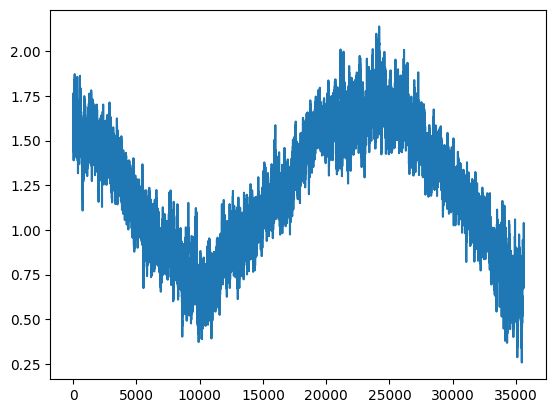

Shape:  torch.Size([32, 248, 35624])  Mean:  tensor(-3.2942e-18, dtype=torch.float64)


In [34]:
plt.plot(scale_data(matrix1, NormalizationType.Z_SCORE_TIMEWISE)[14,:])
plt.show()

scaled_train = scale_data(train_data, NormalizationType.Z_SCORE_TIMEWISE)
print("Shape: " , scaled_train.shape, " Mean: " , torch.mean(scaled_train))